In [2]:
# 1. Imports
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
faro = pd.read_csv("../data/faro_2021_2025.csv")
angra = pd.read_csv("../data/angra_2021_2025.csv")

## Faro Dataset Analysis

In [4]:
faro.head()

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
0,2021-01-01T00:00,12.1,84,0.0,16.0
1,2021-01-01T01:00,11.6,83,0.0,13.7
2,2021-01-01T02:00,11.0,79,0.0,16.6
3,2021-01-01T03:00,10.4,83,0.0,17.1
4,2021-01-01T04:00,10.0,85,0.0,17.1


In [5]:
faro.sample(10)

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
14106,2022-08-11T18:00,23.1,69,0.0,17.6
29303,2024-05-05T23:00,17.4,89,0.0,10.9
20153,2023-04-20T17:00,19.4,64,0.0,12.6
28092,2024-03-16T12:00,21.0,66,0.0,14.7
17269,2022-12-21T13:00,18.1,83,0.0,4.9
12639,2022-06-11T15:00,32.2,28,0.0,14.8
38444,2025-05-21T20:00,24.2,58,0.0,18.3
40252,2025-08-05T04:00,22.6,91,0.0,10.6
43624,2025-12-23T16:00,16.3,68,0.0,16.1
32084,2024-08-29T20:00,26.0,56,0.0,12.3


In [6]:
faro.shape

(43824, 5)

In [7]:
faro.info()

<class 'pandas.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   time                  43824 non-null  str    
 1   temperature_2m        43824 non-null  float64
 2   relative_humidity_2m  43824 non-null  int64  
 3   precipitation         43824 non-null  float64
 4   wind_speed_10m        43824 non-null  float64
dtypes: float64(3), int64(1), str(1)
memory usage: 1.7 MB


In [8]:
faro.isnull().sum()

time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
wind_speed_10m          0
dtype: int64

In [9]:
faro.duplicated().sum()

np.int64(0)

In [10]:
faro["time"] = pd.to_datetime(faro["time"])

In [11]:
faro["time"].min(), faro["time"].max()

(Timestamp('2021-01-01 00:00:00'), Timestamp('2025-12-31 23:00:00'))

In [12]:
faro["time"].is_monotonic_increasing

True

In [13]:
expected = pd.date_range(
    start=faro["time"].min(),
    end=faro["time"].max(),
    freq="h"
)

len(expected) - len(faro)

0

In [14]:
faro.describe().round(2)

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
count,43824,43824.00,43824.00,43824.00,43824.00
mean,2023-07-02 23:29:59.999999,18.81,69.34,0.06,12.85
min,2021-01-01 00:00:00,2.50,8.00,0.00,0.00
25%,2022-04-02 11:45:00,14.80,57.00,0.00,7.60
50%,2023-07-02 23:30:00,18.40,71.00,0.00,11.90
75%,2024-10-01 11:15:00,22.60,84.00,0.00,17.10
max,2025-12-31 23:00:00,39.50,100.00,22.80,56.60
std,NaN,5.52,17.64,0.41,6.91


In [15]:
faro["rain_event"] = (faro["precipitation"] > 0).astype(int)

Related to rain_event now

In [16]:
faro["rain_event"].value_counts()

rain_event
0    39945
1     3879
Name: count, dtype: int64

In [17]:
faro["rain_event"].value_counts(normalize=True).mul(100).round(2)

rain_event
0    91.15
1     8.85
Name: proportion, dtype: float64

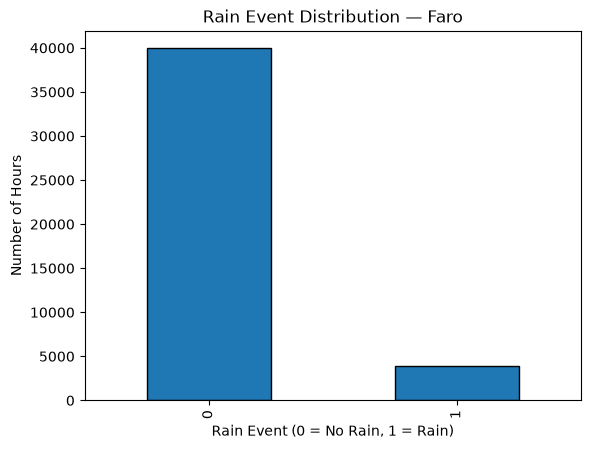

In [18]:
faro["rain_event"].value_counts().sort_index().plot(
    kind="bar",
    title="Rain Event Distribution — Faro", edgecolor="black"
)

plt.xlabel("Rain Event (0 = No Rain, 1 = Rain)")
plt.ylabel("Number of Hours")
plt.show()

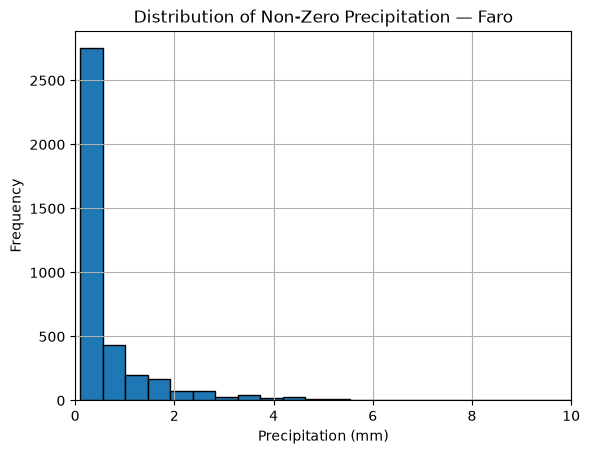

In [19]:
faro.loc[faro["precipitation"] > 0, "precipitation"].hist(bins=50, edgecolor="black")

plt.xlabel("Precipitation (mm)")
plt.ylabel("Frequency")
plt.xlim(0, 10)
plt.title("Distribution of Non-Zero Precipitation — Faro")
plt.show()

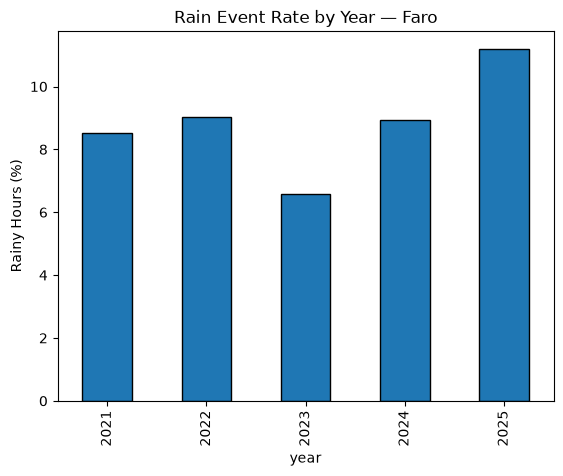

In [20]:
faro["year"] = faro["time"].dt.year

yearly_rain = faro.groupby("year")["rain_event"].mean() * 100

yearly_rain.plot(
    kind="bar",
    title="Rain Event Rate by Year — Faro", edgecolor="black"
)

plt.ylabel("Rainy Hours (%)")
plt.show()

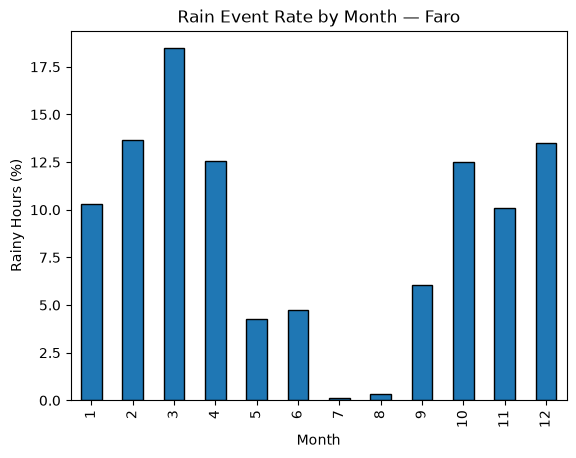

In [21]:
faro["month"] = faro["time"].dt.month

monthly_rain = faro.groupby("month")["rain_event"].mean() * 100

monthly_rain.plot(
    kind="bar",
    title="Rain Event Rate by Month — Faro", edgecolor="black"
)

plt.xlabel("Month")
plt.ylabel("Rainy Hours (%)")
plt.show()

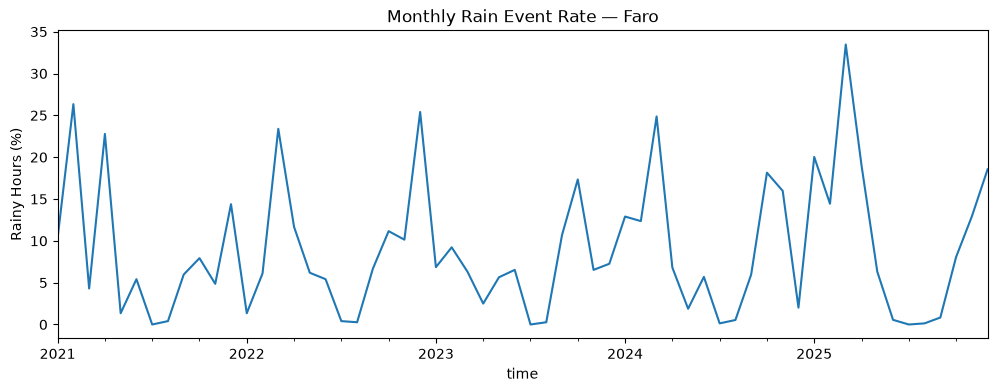

In [22]:
monthly = (
    faro
    .set_index("time")["rain_event"]
    .resample("ME")
    .mean() * 100
)

monthly.plot(
    figsize=(12, 4),
    title="Monthly Rain Event Rate — Faro"
)

plt.ylabel("Rainy Hours (%)")
plt.show()

## Angra Dataset Analysis

In [23]:
angra.head()

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
0,2021-01-01T00:00,13.7,82,0.0,12.6
1,2021-01-01T01:00,13.7,83,0.0,13.4
2,2021-01-01T02:00,13.6,84,0.0,12.6
3,2021-01-01T03:00,13.4,86,0.0,12.6
4,2021-01-01T04:00,13.4,88,0.0,12.8


In [24]:
angra.sample(10)

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
16641,2022-11-25T09:00,18.3,95,2.8,38.8
25971,2023-12-19T03:00,13.6,92,2.4,16.1
21319,2023-06-08T07:00,16.5,86,0.0,12.8
24613,2023-10-23T13:00,20.3,71,0.0,19.2
25439,2023-11-26T23:00,18.9,100,0.4,18.1
19385,2023-03-19T17:00,16.5,73,0.2,21.3
19187,2023-03-11T11:00,16.7,99,3.1,22.2
1110,2021-02-16T06:00,12.2,72,0.0,12.4
42283,2025-10-28T19:00,16.3,76,0.0,10.7
1793,2021-03-16T17:00,16.7,90,1.0,19.3


In [25]:
angra.shape

(43824, 5)

In [26]:
angra.info()

<class 'pandas.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   time                  43824 non-null  str    
 1   temperature_2m        43824 non-null  float64
 2   relative_humidity_2m  43824 non-null  int64  
 3   precipitation         43824 non-null  float64
 4   wind_speed_10m        43824 non-null  float64
dtypes: float64(3), int64(1), str(1)
memory usage: 1.7 MB


In [27]:
angra.isnull().sum()

time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
wind_speed_10m          0
dtype: int64

In [28]:
angra.duplicated().sum()

np.int64(0)

In [29]:
angra["time"] = pd.to_datetime(angra["time"])

In [30]:
angra["time"].min(), angra["time"].max()

(Timestamp('2021-01-01 00:00:00'), Timestamp('2025-12-31 23:00:00'))

In [31]:
angra["time"].is_monotonic_increasing

True

In [32]:
expected = pd.date_range(
    start=angra["time"].min(),
    end=angra["time"].max(),
    freq="h"
)

len(expected) - len(angra)

0

In [33]:
angra.describe().round(2)

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
count,43824,43824.00,43824.00,43824.00,43824.00
mean,2023-07-02 23:29:59.999999,17.63,85.29,0.21,13.88
min,2021-01-01 00:00:00,6.30,46.00,0.00,0.00
25%,2022-04-02 11:45:00,15.00,77.00,0.00,7.10
50%,2023-07-02 23:30:00,17.20,87.00,0.00,12.60
75%,2024-10-01 11:15:00,20.20,95.00,0.10,19.20
max,2025-12-31 23:00:00,29.40,100.00,19.70,58.40
std,NaN,3.55,10.93,0.69,8.41


In [34]:
angra["rain_event"] = (angra["precipitation"] >= 0.1).astype(int)

In [35]:
angra["rain_event"].value_counts()

rain_event
0    26790
1    17034
Name: count, dtype: int64

In [37]:
angra["rain_event"].value_counts(normalize=True).mul(100).round(2)

rain_event
0    61.13
1    38.87
Name: proportion, dtype: float64

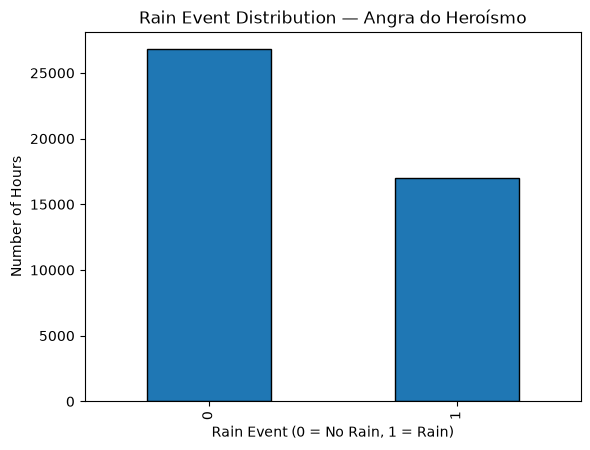

In [36]:
angra["rain_event"].value_counts().sort_index().plot(
    kind="bar",
    title="Rain Event Distribution — Angra do Heroísmo",
    edgecolor="black"
)

plt.xlabel("Rain Event (0 = No Rain, 1 = Rain)")
plt.ylabel("Number of Hours")
plt.show()

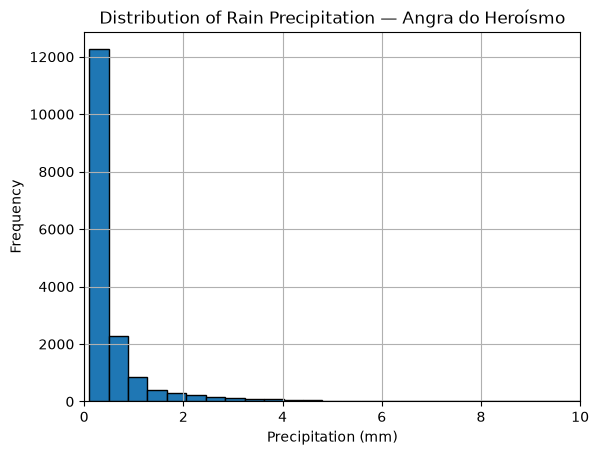

In [38]:
angra.loc[
    angra["precipitation"] >= 0.1,
    "precipitation"
].hist(
    bins=50,
    edgecolor="black"
)

plt.xlabel("Precipitation (mm)")
plt.ylabel("Frequency")
plt.xlim(0, 10)
plt.title("Distribution of Rain Precipitation — Angra do Heroísmo")
plt.show()

In [39]:
angra["year"] = angra["time"].dt.year

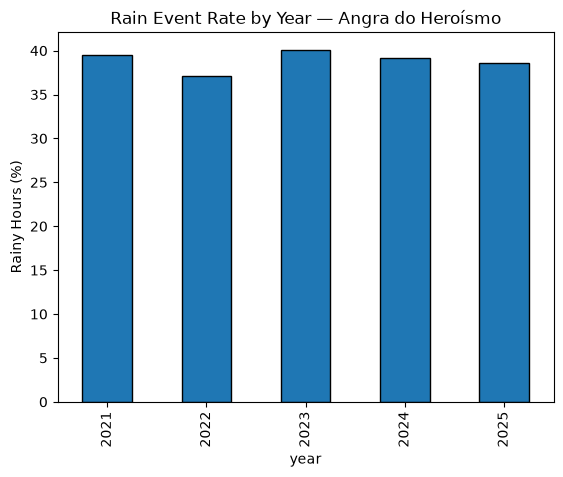

In [40]:
yearly_rain_angra = (
    angra.groupby("year")["rain_event"].mean() * 100
)

yearly_rain_angra.plot(
    kind="bar",
    title="Rain Event Rate by Year — Angra do Heroísmo",
    edgecolor="black"
)

plt.ylabel("Rainy Hours (%)")
plt.show()

In [41]:
angra["month"] = angra["time"].dt.month

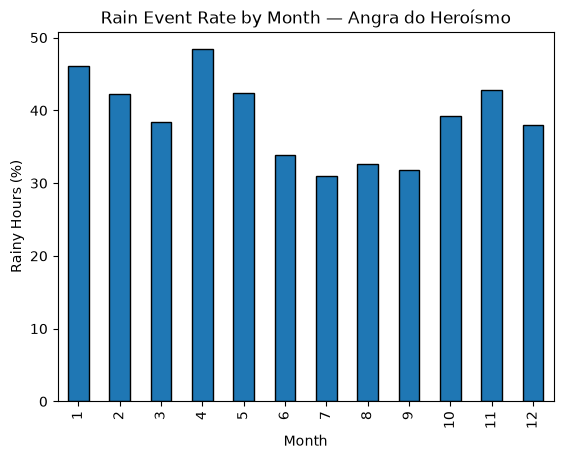

In [42]:
monthly_rain_angra = (
    angra.groupby("month")["rain_event"].mean() * 100
)

monthly_rain_angra.plot(
    kind="bar",
    title="Rain Event Rate by Month — Angra do Heroísmo",
    edgecolor="black"
)

plt.xlabel("Month")
plt.ylabel("Rainy Hours (%)")
plt.show()

Rolling rate?

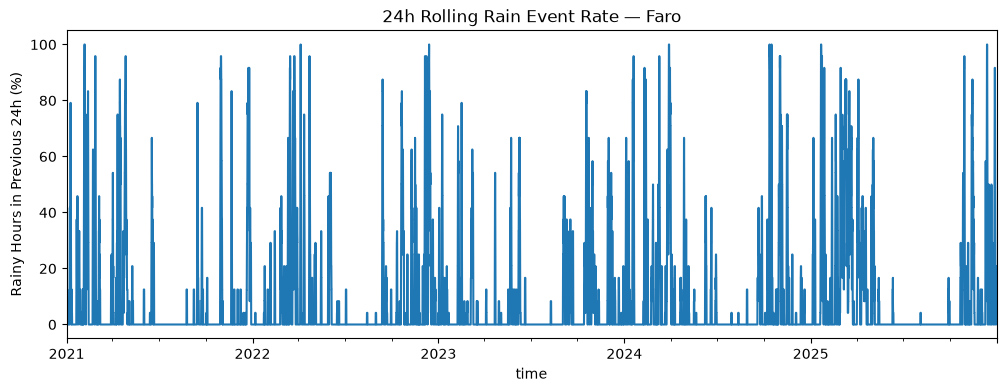

In [43]:
# 24-hour rolling rain-event rate
faro["rain_24h_rate"] = (
    faro["rain_event"]
    .rolling(24)
    .mean() * 100
)

faro.plot(
    x="time",
    y="rain_24h_rate",
    figsize=(12, 4),
    legend=False
)

plt.ylabel("Rainy Hours in Previous 24h (%)")
plt.title("24h Rolling Rain Event Rate — Faro")
plt.show()

In [44]:
# Consecutive rain-free periods
groups = faro["rain_event"].ne(faro["rain_event"].shift()).cumsum()

dry_spells_faro = (
    faro[faro["rain_event"] == 0]
    .groupby(groups)
    .size()
)

dry_spells_faro.describe().round(2)

count    1039.00
mean       38.45
std       118.63
min         1.00
25%         2.00
50%         5.00
75%        20.00
max      1549.00
dtype: float64

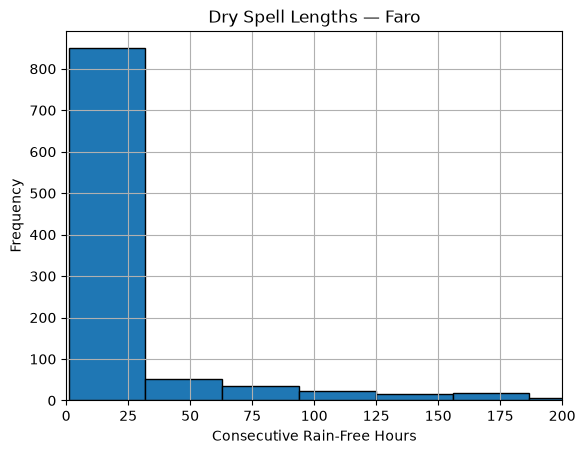

In [45]:
dry_spells_faro.hist(
    bins=50,
    edgecolor="black"
)

plt.xlabel("Consecutive Rain-Free Hours")
plt.ylabel("Frequency")
plt.title("Dry Spell Lengths — Faro")
plt.xlim(0, 200)
plt.show()

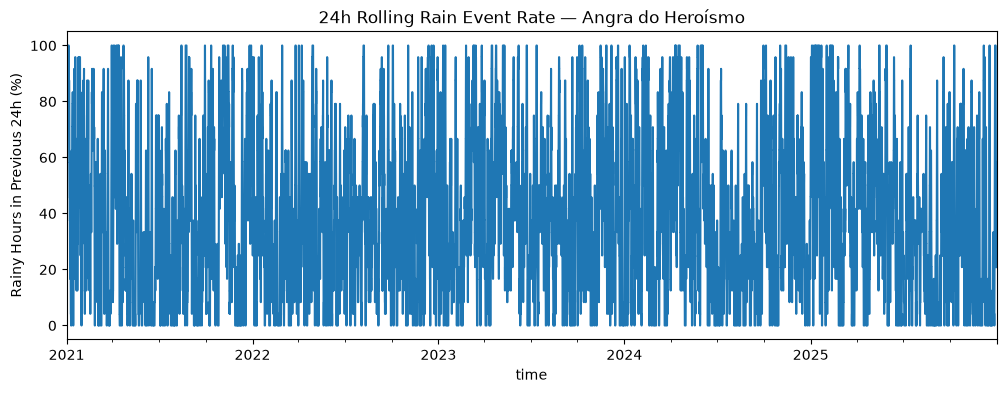

In [46]:
# 24-hour rolling rain-event rate
angra["rain_24h_rate"] = (
    angra["rain_event"]
    .rolling(24)
    .mean() * 100
)

angra.plot(
    x="time",
    y="rain_24h_rate",
    figsize=(12, 4),
    legend=False
)

plt.ylabel("Rainy Hours in Previous 24h (%)")
plt.title("24h Rolling Rain Event Rate — Angra do Heroísmo")
plt.show()

In [47]:
# Consecutive rain-free periods
groups = angra["rain_event"].ne(angra["rain_event"].shift()).cumsum()

dry_spells_angra = (
    angra[angra["rain_event"] == 0]
    .groupby(groups)
    .size()
)

dry_spells_angra.describe().round(2)

count    2902.00
mean        9.23
std        12.31
min         1.00
25%         1.00
50%         4.00
75%        13.00
max       108.00
dtype: float64

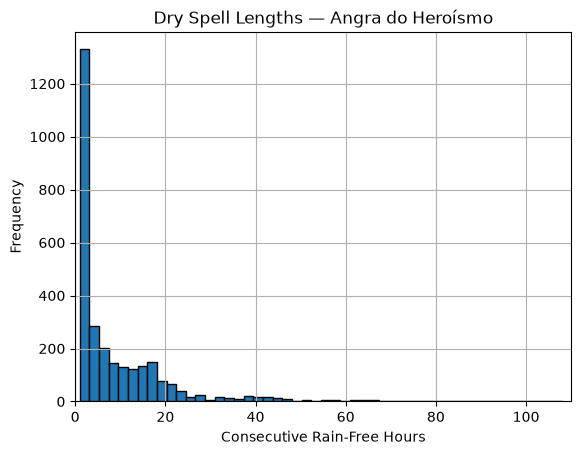

In [49]:
dry_spells_angra.hist(
    bins=50,
    edgecolor="black"
)

plt.xlabel("Consecutive Rain-Free Hours")
plt.ylabel("Frequency")
plt.title("Dry Spell Lengths — Angra do Heroísmo")
plt.xlim(0, 110)
plt.show()